# PopCILA for Spatial Transcriptomics: Phenotype-Guided Spatial CCI Mapping

## Phenotype-associated LRI discovery

This tutorial walks you through using PopCILA to discover phenotype-associated ligand–receptor interactions (LRIs) from cohort-scale bulk transcriptomic data.

To get started, prepare (i) a bulk gene expression matrix and (ii) the corresponding sample-level phenotype annotations. PopCILA supports binary, continuous, ordinal, and right-censored survival phenotype types.

See our manuscript for additional background and methodological details.

### import

In [1]:
import warnings
warnings.filterwarnings("ignore")
import PopCILA as pc
import pandas as pd
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

### Loading Bulk data and data processing

First, we load the bulk data and its corresponding clinical meta-data. Note that the expression matrix we load should have samples as columns and genes as rows, while the clinical meta-file should have sample as rows and clinical informations as columns.

In [2]:
expr_df = pd.read_csv('data/OSSC_expr.csv', header=0, index_col=0) 
clin_df = pd.read_csv('data/OSSC_clinical_meta.csv',index_col=0, header=0)

Next, we use PopCILA to filter the bulk expression matrix: We select genes that express ligands and receptors, and filter out genes with an average expression level below 1 (log2(tpm+1)). 

In [3]:
lr_expr_pairs, lr_expr_df = pc.filter_Bulkdata(expr_df,threshold=1)

Of course, you can provide PopCILA with a customized ligand-receptor database according to your needs, and choose whether to filter out lowly expressed genes. The ligand-receptor database you provide should be in CSV format and must have two columns named "ligand" and "receptor".

In [ ]:
lr_expr_pairs, lr_expr_df = pc.filter_Bulkdata(bulk_data = expr_df,lr_db_path = "Human-2020-Cabello-Aguilar-LR-pairs.csv")

Next, we process the sample metadata to obtain the phenotypic constraints and other relevant information required for PopCILA analysis. 

For binary phenotype, run the following code: 

In [ ]:
S, Y, lr_expr_df, phenotype_interval, clin_df = pc.getBinaryConstraint(
    clin_df=clin_df,
    lr_expr_df=lr_expr_df,
    by='tissue_type', #The column names of the phenotypes we focused in clin_df
    phenotype_of_interest='Tumor' #The phenotype we concerned in the COVID column
    )

**Note:** S is the phenotypic constraint used by PopCILA to identify LRIs, and Y is the phenotypic constraint used to identify CCIs (used later in downstream projection step to identify phenotype-associated CCIs / CCI-active cells or spots).

For continuous phenotype, run the following code:

In [ ]:
S = pc.getLinearConstraint(
    clin_df,
    by = 'HFD-45' #The column names of the phenotypes we focused in clin_df
    ) 
Y = clin_df.loc[lr_expr_df.columns]['HFD-45'].values.reshape(-1, 1)

For ordinal phenotype, run the following code:

In [4]:
S, Y, lr_expr_df, phenotype_interval, clin_df = pc.getOrderedConstraint(
    clin_df=clin_df,
    lr_expr_df=lr_expr_df,
    by='ajcc_pathologic_stage.diagnoses', #The column names of the phenotypes we focused in clin_df
)

**Note:** Before processing ordinal variables, PopCILA requires them to be converted into integer-valued numeric variables starting from 1. For example,'Stage I' can be converted to 1, 'Stage II' can be converted to 2 and 'Stage III' can be converted to 3. 

For survival phenotype, run the following code:

In [ ]:
S = pc.getProgConstraint(
    clin_df,
    interest=1 #interest=1 indicates focusing on poorer prognoses, while interest=0 indicates the opposite.
    )
time, event = pc.getCoxelement(clin_df) #time and event are the phenotypic constraint used to identify CCI.

**Note:** clin_df must include the columns 'OS.time'(survival time) and 'OS'(survival state), and the sample order should match that of the bulk expression matrix. In addition, PopCILA.getProgConstraint function would converts survival-related phenotypes into a linearized score using the complete rank method and adds it to clin_df for association analysis.

### Building Communication Potential Matrix

In [5]:
comm_matrix = pc.build_communication_matrix(lr_expr_pairs, lr_expr_df)

### Identify phenotype-associated LRIs

Before performing phenotype-associated LRI analysis using PopCILA, we need to estimate the number of potential biological patterns in this bulk cohort using the elbow method. Users can control the number of identified potential biological patterns by adjusting the elbow point (eii_tol). PopCILA defaults to an eii_tol value of 0.05. 

In [6]:
optimal_K = pc.select_k_components(X = comm_matrix.T.values.astype(float), S=S, lambda_pheno=0.10, lambda_en=0.05, eii_tol = 0.05,verbose=True)
print(optimal_K)

[K=2] recon_err=0.661169
[K=3] recon_err=0.560974
[K=4] recon_err=0.495575
   eii=0.3949
[K=5] recon_err=0.446113
   eii=0.2300
[K=6] recon_err=0.419664
   eii=0.1095
[K=7] recon_err=0.395685
   eii=0.0903
[K=8] recon_err=0.376049
   eii=0.0689
[K=9] recon_err=0.361856
   eii=0.0474
[Elbow] Stop at K=9, select K=8
8


Then, we execute PopCILA to perform phenotype-guided decomposition of the signaling potential matrix to identify specific signaling patterns.

In [7]:
W, H, hist = pc.LRcommMining(X = comm_matrix.T.values.astype(float), S=S, n_components=optimal_K, rho=0.75, lambda_pheno=0.10, lambda_en=0.05,maxiter=8000)

[Balance] alpha=0.130979, beta=0.0360851 (targets: pheno=0.1, en=0.05)
Iteration 0/8000, Loss: 0.439425
Iteration 200/8000, Loss: 0.434162
Iteration 400/8000, Loss: 0.430629
Iteration 600/8000, Loss: 0.428013
Iteration 800/8000, Loss: 0.426086
Iteration 1000/8000, Loss: 0.424663
Iteration 1200/8000, Loss: 0.423638
Iteration 1400/8000, Loss: 0.422891
Iteration 1600/8000, Loss: 0.422327
Iteration 1800/8000, Loss: 0.421880
Iteration 2000/8000, Loss: 0.421511
Iteration 2200/8000, Loss: 0.421196
Iteration 2400/8000, Loss: 0.420918
Iteration 2600/8000, Loss: 0.420666
Iteration 2800/8000, Loss: 0.420437
Iteration 3000/8000, Loss: 0.420227
Early stopped at iter 3166 (patience=20)


Using the association analysis provided by PopCILA, we can evaluate which patterns are more relevant to the phenotypes of interest.

**Note:** It is important to note that the association analysis provided by PopCILA requires that the phenotype column in the input, i.e., the phenotype column in clinical meta-data, must be a numerical variable. Therefore, we recommend that users convert phenotypes to numerical values in the clinical meta-data in advance. For example, 'Tumor' can be converted to 1, and 'Normal' can be converted to 0.  'Stage I' can be converted to 1, 'Stage II' can be converted to 2 and 'Stage IV' can be converted to 4. Finally, PopCILA considers a positive correlation to be more related to phenotypes with higher numerical values.

For binary phenotype, run the following code:

In [ ]:
phenotype_types = {"COVID": "binary"} #The column name of the phenotype in clin_df: The type of the phenotype ("binary","continuous","ordinal")

For continuous phenotype, run the following code:

In [ ]:
phenotype_types = {"HFD-45": "continuous"} #The column name of the phenotype in clin_df: The type of the phenotype ("binary","continuous","ordinal")

For ordinal phenotype, run the following code:

In [8]:
phenotype_types = {"ajcc_pathologic_stage.diagnoses": "ordinal"}  #The column name of the phenotype in clin_df: The type of the phenotype ("binary","continuous","ordinal")                 

For survival phenotype, run the following code:

In [ ]:
phenotype_types = {"completerank": "continuous"}#The column name of the phenotype in clin_df: The type of the phenotype ("binary","continuous","ordinal")

**Note:** The completerank attribute is a linear variable derived from OS and OS.time using the PopCILA.getProgConstraint function, and it is stored in clin_df.

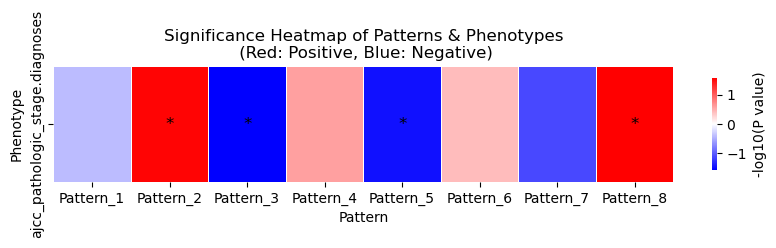

In [9]:
result = pc.Singleassociationanalysis(W, clin_df, phenotype_types)
pc.plot_significance_heatmap(result)

For binary phenotype and ordinal phenotype, PopCILA’s association analysis additionally integrates complementary evidence from
visualization-based analyses

We visualize the distribution of pattern scores for each signaling pattern obtained from the PopCILA. 

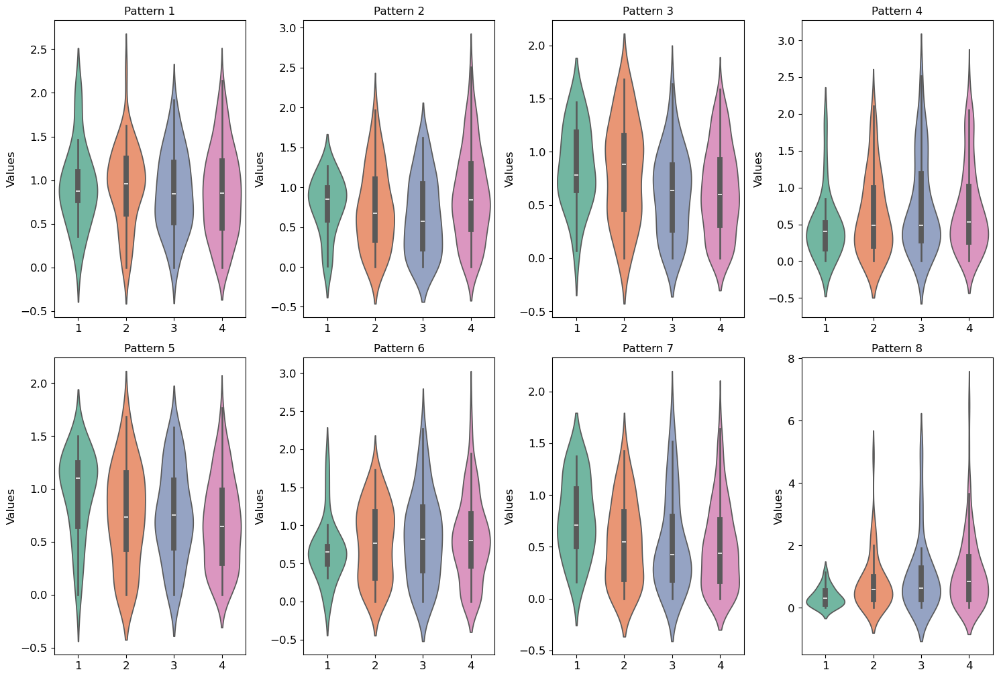

In [10]:
pc.getPatternDistribution(W, phenotype_interval = phenotype_interval)

We recommend users to identify phenotype-asscoiated patterns by combining both visualization-based and regression-based result.

In [11]:
res = pc.getLRcomm(W,H,comm_matrix,
                   patterns = [2,4,6,8], 
                   lr_expr_pairs = lr_expr_pairs,
                   zscore_threshold = 2.5
                  )

**Note:** Users can flexibly adjust zscore_threshold to control the number of LRIs identified by PopCILA. By default, PopCILA sets zscore_threshold = 2.

In [12]:
pc.plot_sankey(res, width=800, height=600, font_size=20)

## Phenotype-associated CCI discovery

Guided by the phenotypic information, PopCILA will project these LRIs into spatial transcriptomic contexts to uncover how they manifest as specific cell–cell communication events within the tissue context that underlie phenotypic variation.

### Loading spatial transcriptome data and data processing

In [13]:
adata = sc.read_visium('data/GSM6339631_s1/', 
                       count_file='GSM6339631_s1_filtered_feature_bc_matrix.h5',
                       load_images=True)

In [14]:
sc.pp.calculate_qc_metrics(adata, inplace=True)
sc.pp.filter_genes(adata, min_cells=10)
sc.pp.filter_cells(adata, min_genes=10)
if adata.var_names.duplicated().any():
    adata.var_names_make_unique()
adata = pc.counts2log1tpm(adata) #transforming the count data in adata to the log (1 + TPM) format.
sc.pp.calculate_qc_metrics(adata, inplace=True)

PopCILA can integrate histological images to calculate the spatial relationships between spots (adjacency matrix), enabling more rigorous identification of phenotype-associated CCIs in the spatial transcriptomics.

Extract the high-resolution (hires) image from the spatial transcriptomics data (adata), ensuring that the pixel values are in the range of 0-255 (standard uint8 image format).

In [15]:
sample_id = list(adata.uns['spatial'].keys())[0]  
hires_img = adata.uns['spatial'][sample_id]['images']['hires']  
print(hires_img.dtype, hires_img.min(), hires_img.max())#Make sure the data is unit8 level 255

float32 0.0 0.9098039


If not, converting the image to uint level 255 using the code below

In [16]:
hires_img = (hires_img * 255).astype(np.uint8) # float 32 -> uint 8
print(hires_img.dtype, hires_img.min(), hires_img.max())#Make sure the data is unit8 level 255

uint8 0 232


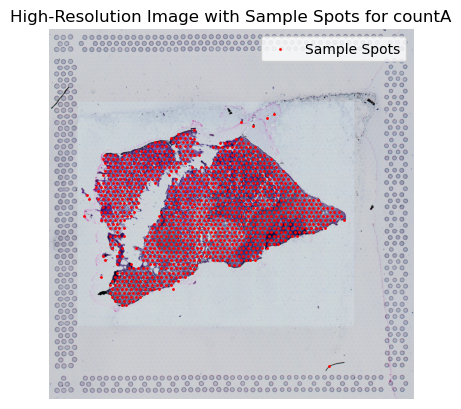

In [17]:
#Set coordinates
x_pixel = np.round(adata.obsm['spatial'][:,1]*adata.uns['spatial'][sample_id]['scalefactors']['tissue_hires_scalef']).astype(int)
y_pixel = np.round(adata.obsm['spatial'][:,0]*adata.uns['spatial'][sample_id]['scalefactors']['tissue_hires_scalef']).astype(int)

#Test coordinates on the image
plt.imshow(hires_img)
plt.scatter(y_pixel, x_pixel, c='red', s=1, label='Sample Spots') 
plt.title(f"High-Resolution Image with Sample Spots for {sample_id}")
plt.axis("off")
plt.legend()
plt.show()

Calculating adjacent matrix

In [18]:
b=adata.uns['spatial'][sample_id]['scalefactors']['spot_diameter_fullres'] #Diameter of spot
adj = pc.spatial_knn_graph(x=x_pixel, y=y_pixel, x_pixel=x_pixel, y_pixel=y_pixel, image=hires_img, histology=True, beta=b, alpha=1.0, n_neighbors=20)

Building feature matrix [x, y, z] using histology image...


If histlogy image is not available, PopCILA calculate the adjacent matrix using the function below

In [ ]:
adj = pc.spatial_knn_graph(x=adata.obsm["spatial"][:, 1], y=adata.obsm["spatial"][:, 0], histology=False, n_neighbors=20)

Filtering the genes in the spatial transcriptomics data based on the phenotype-associated LRIs identified by PopCILA, we obtain the ligand-receptor expression vectors for each spot. We then calculate the pairwise correlation with the ligand-receptor expression vectors of the bulk samples.

In [19]:
st_lr_expr_df, st_lr_expr_pairs = pc.filter_stRNAdata(res, adata)
print("Expression matrix shape:", st_lr_expr_df.shape)
X = pc.calculate_correlation_matrix(lr_expr_df, st_lr_expr_df,block_size=2000)

Expression matrix shape: (79, 1182)
|**************************************************|
Performing quality-check for the correlations
The five-number summary of correlations:
Min: -0.13192065060138702
25th Percentile: 0.49077440053224564
Median: 0.5825734734535217
75th Percentile: 0.6551273614168167
Max: 0.8551994562149048
|**************************************************|


### Identify phenotype-associated CCI active regions

PopCILA will select different regression models for optimization based on the different phenotype type (method = 'binary' or 'linear' or 'cox' or 'ordinal').

For binary phenotype, run the following code:

In [ ]:
CCcomm = pc.CCcommInfer(method='binary',X = X, y = Y, alpha=0, lambda_=0.05, Omega=adj, learning_rate=0.0001, n_epochs=1000)

For continuous phenotype, run the following code:

In [ ]:
CCcom = pc.CCcommInfer(method="linear", X = X, y = phe, alpha=0, lambda_=0.05, Omega=adj, learning_rate=0.0001, n_epochs=1000)

For ordinal phenotype, run the following code:

In [20]:
CCcomm = pc.CCcommInfer(method='ordinal',X = X, y = Y, alpha=0, lambda_=0.05, Omega=adj, learning_rate=0.0001, n_epochs=1000)

For survival phenotype, run the following code:

In [ ]:
CCcom = pc.CCcommInfer(method="cox", X = X,time = time,event = event, alpha=0, lambda_=0.05, Omega=adj, learning_rate=0.0001, n_epochs=1000)

Based on the optimization results from PopCILA, we set the subset of cells with the positive effect-size (beta weights > 0 by default) as phenotype-associated CCI active region (spots with beta > 0) for subsequent analysis.

Building feature matrix [x, y] only...


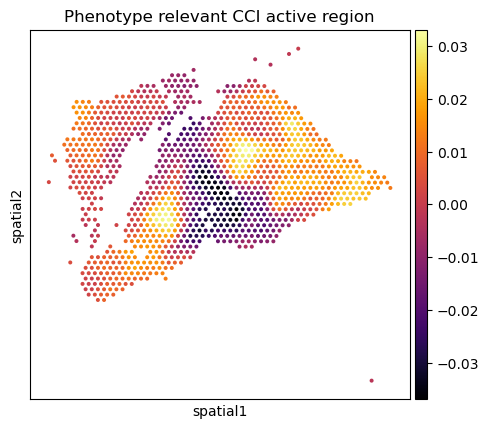

In [21]:
adata.obs['beta'] = CCcomm.model.linear.weight.detach().cpu().squeeze().numpy()
adj_2d=pc.spatial_knn_graph(x=adata.obsm["spatial"][:, 1], y=adata.obsm["spatial"][:, 0], histology=False, n_neighbors=6)
adata.obs['refined_beta']=pc.refine_beta(sample_id=adata.obs.index.tolist(), pred=adata.obs['beta'].tolist(), adj=adj_2d)
sc.pl.spatial(
    adata,
    img_key=None,
    color='refined_beta',          
    cmap='inferno',        #  'viridis', 'plasma', 'inferno' 
    spot_size=b,        
    title="Phenotype relevant CCI active region", 
    colorbar_loc='right',
)

PopCILA identifies putative phenotype-associated CCIs via spatially-aware visualization strategy by generate spot-wise CCI activity scores, enabling robust localization and interpretation of key intercellular interactions underlying complex phenotypes.

In [22]:
lr_list = pc.extract_lr_tf(res)

lr_df = pc.compute_spatial_activity(
    adata,
    lr_pairs=lr_list,
    subset_key="refined_beta",
    subset_condition=">0", #If you are interested in negative correlations, set this to "<0"
    clip_activity = True
)

Using subset: refined_beta >0, 764 spots retained.
Computed LR activity for FN1-ITGA5 (clipped at 0.95 quantile=32.1).
Computed LR activity for COL1A1-ITGA11 (clipped at 0.95 quantile=21.03).
Computed LR activity for COL1A2-ITGA11 (clipped at 0.95 quantile=18.14).
Computed LR activity for MDK-SDC1 (clipped at 0.95 quantile=42.59).
Computed LR activity for COL11A1-DDR1 (clipped at 0.95 quantile=11.66).
Computed LR activity for COL11A1-ITGB1 (clipped at 0.95 quantile=10.32).
Computed LR activity for MDK-SDC4 (clipped at 0.95 quantile=35.73).
Computed LR activity for COL11A1-ITGA2 (clipped at 0.95 quantile=6.512).
Computed LR activity for FN1-SDC2 (clipped at 0.95 quantile=19.26).
Computed LR activity for COL1A1-DDR2 (clipped at 0.95 quantile=21.77).
Computed LR activity for COL3A1-DDR2 (clipped at 0.95 quantile=18.68).
Computed LR activity for CSF2-ITGB1 (clipped at 0.95 quantile=27.09).
Computed LR activity for MMP2-SDC2 (clipped at 0.95 quantile=15.22).
Computed LR activity for COL1A1-

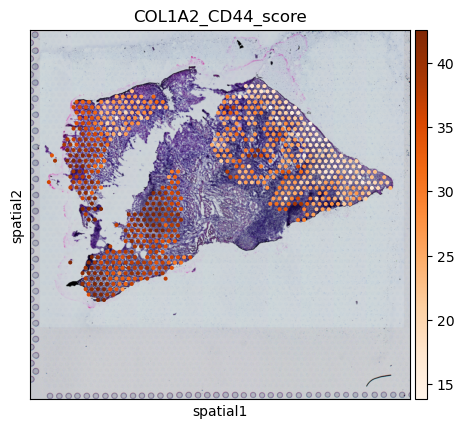

In [23]:
sc.pl.spatial(adata, color="COL1A2_CD44_score",cmap='Oranges')

## Phenotype-associated intercellular signaling cascades discovery

Beyond ligand–receptor–mediated CCIs, PopCILA further resolves phenotype-associated intercellular signaling at the level of downstream transcriptional regulation by constructing and prioritizing phenotype-associated ligand–receptor–transcription factor (L–R–TF) signaling cascades and mapping them back to specific cell and tissue contexts.

In spatial transcriptomics, PopCILA starts from phenotype-associated CCI-active spots(region) and incorporates spatial autocorrelation and co-localization constraints to preferentially retain spatially coherent L-R-TF signaling candidates.

In [24]:
adata1 = adata[adata.obs['refined_beta'] > 0 ]  #The negative correlations: adata1 = adata[adata.obs['refined_beta'] < 0 ]
links_df = pc.find_spatial_LRTF_links(
    adata=adata1,
    res=res,
    moranI_threshold=0.15, #Users can adjust moranI_threshold to control the number of selected candidates.
    k=20,
    permutations=499
)

Building spatial neighbors (k=20) ...
Calculating global Moran's I for 720 candidate genes ...


  0%|          | 0/499 [00:00<?, ?/s]

Retained 149 spatially variable genes (I > 0.15).
Filtered LR pairs: 41, RT pairs: 264
Computing Bivariate Moran's I for ligand–receptor pairs ...
40 significant LR pairs retained.
Restrict RT pairs to receptors from significant LR pairs: 263 RT pairs left.
Computing Bivariate Moran's I for receptor–TF pairs ...
223 significant RT pairs retained.
Total 487 ligand–receptor–TF chains identified.


Similar to identifying phenotype-associated signals at the LR level, PopCILA applies the same approach to identify phenotype-associated signals at the L–R–TF level.

In [25]:
lrtf_expr, lrtf_expr_df = pc.filter_Bulkdata_LRTF(expr_df,links_df,threshold=1)
comm_matrix_lrtf = pc.build_LRTF_communication_matrix(lrtf_expr, lrtf_expr_df)
comm_matrix_lrtf = comm_matrix_lrtf[comm_matrix.columns]
optimal_K = pc.select_k_components(X = comm_matrix_lrtf.T.values.astype(float), S=S, lambda_pheno=0.10, lambda_en=0.05, eii_tol = 0.05,verbose=True)

[K=2] recon_err=0.218062
[K=3] recon_err=0.180438
[K=4] recon_err=0.151033
   eii=0.4387
[K=5] recon_err=0.135491
   eii=0.1882
[K=6] recon_err=0.122705
   eii=0.1341
[K=7] recon_err=0.111336
   eii=0.1065
[K=8] recon_err=0.101216
   eii=0.0866
[K=9] recon_err=0.092038
   eii=0.0728
[K=10] recon_err=0.084555
   eii=0.0560
[K=11] recon_err=0.077384
   eii=0.0510
[K=12] recon_err=0.071236
   eii=0.0419
[Elbow] Stop at K=12, select K=11


Then, we execute PopCILA to perform phenotype-guided decomposition of the signaling potential matrix to identify specific L-R-TF signaling patterns.

In [26]:
W_lrtf, H_lrtf, hist = pc.LRcommMining(X = comm_matrix_lrtf.T.values.astype(float), S=S, n_components=optimal_K, rho=0.75, lambda_pheno=0.10, lambda_en=0.05,maxiter=8000)

[Balance] alpha=0.0378424, beta=0.00725318 (targets: pheno=0.1, en=0.05)
Iteration 0/8000, Loss: 0.094719
Iteration 200/8000, Loss: 0.091986
Iteration 400/8000, Loss: 0.090493
Iteration 600/8000, Loss: 0.089542
Iteration 800/8000, Loss: 0.088855
Iteration 1000/8000, Loss: 0.088329
Iteration 1200/8000, Loss: 0.087929
Iteration 1400/8000, Loss: 0.087622
Iteration 1600/8000, Loss: 0.087386
Early stopped at iter 1649 (patience=20)


Using the association analysis provided by PopCILA, we can evaluate which patterns are more relevant to the phenotypes of interest.

For binary phenotype, run the following code:

In [ ]:
phenotype_types = {"COVID": "binary"} #The column name of the phenotype in clin_df: The type of the phenotype ("binary","continuous","ordinal")

For continuous phenotype, run the following code:

In [ ]:
phenotype_types = {"HFD-45": "continuous"} #The column name of the phenotype in clin_df: The type of the phenotype ("binary","continuous","ordinal")

For ordinal phenotype, run the following code:

In [27]:
phenotype_types = {"ajcc_pathologic_stage.diagnoses": "ordinal"}  #The column name of the phenotype in clin_df: The type of the phenotype ("binary","continuous","ordinal")                 

For survival phenotype, run the following code:

In [ ]:
phenotype_types = {"completerank": "continuous"}#The column name of the phenotype in clin_df: The type of the phenotype ("binary","continuous","ordinal")

**Note:** The completerank attribute is a linear variable derived from OS and OS.time using the PopCILA.getProgConstraint function, and it is stored in clin_df.

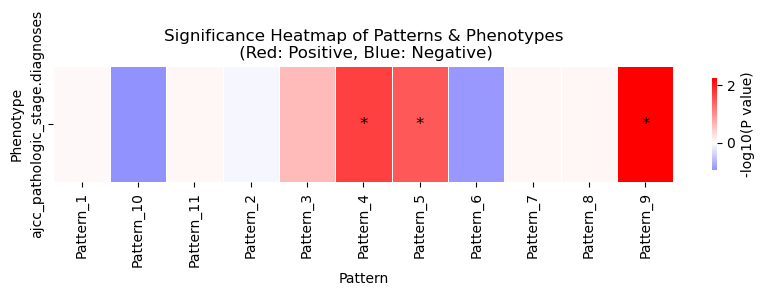

In [28]:
result = pc.Singleassociationanalysis(W_lrtf, clin_df, phenotype_types)
pc.plot_significance_heatmap(result)

For binary phenotype and ordinal, PopCILA’s association analysis additionally integrates complementary evidence from visualization-based analyses

We visualize the distribution of pattern scores for each signaling pattern obtained from the PopCILA.

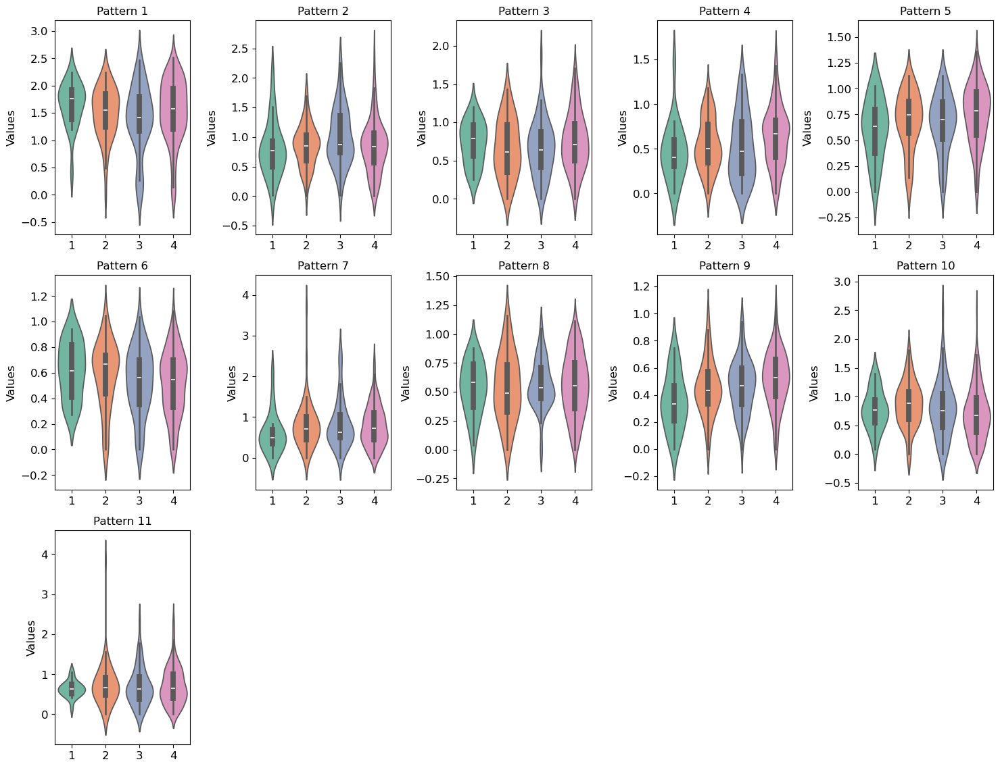

In [29]:
pc.getPatternDistribution(W_lrtf, phenotype_interval = phenotype_interval)

We recommend users to identify phenotype-asscoiated patterns by combining both visualization-based and regression-based result.

In [30]:
res_lrtf= pc.getLRTFcomm(W_lrtf,H_lrtf,comm_matrix_lrtf,patterns = [4,5,9], lr_expr_pairs = lrtf_expr, zscore_threshold = 4)

**Note:** Users can flexibly adjust zscore_threshold to control the number of L–R–TF triplets identified by PopCILA. By default, PopCILA sets zscore_threshold = 2.

In [31]:
pc.plot_sankey_LRTF(res_lrtf, width=800, height=1000,thickness=80,font_size=20)

Finally, PopCILA generate spot-wise L–R–TF activity scores using a spatially aware strategy, enabling localization and interpretation of phenotype-associated intercellular signaling cascades at tissue scale.

In [32]:
lr_list = pc.extract_lr_tf(res_lrtf)
lr_df = pc.compute_spatial_activity(
    adata1,
    lrtf_triplets=lr_list,
    subset_key="refined_beta",
    subset_condition=">0",
    clip_activity = True
)

Using subset: refined_beta >0, 764 spots retained.
Computed LRTF activity for COL11A1-ITGB1-HIF1A (clipped at 0.95 quantile=6.237).
Computed LRTF activity for COL11A1-ITGB1-YBX1 (clipped at 0.95 quantile=7.226).
Computed LRTF activity for HSP90AA1-FGFR3-TSC22D3 (clipped at 0.95 quantile=9.044).
Computed LRTF activity for FN1-ITGA6-TSC22D3 (clipped at 0.95 quantile=9.49).
Computed LRTF activity for COL1A1-ITGAV-TSC22D3 (clipped at 0.95 quantile=10.9).
Computed LRTF activity for HMGB1-SDC1-TSC22D3 (clipped at 0.95 quantile=8.346).
Computed LRTF activity for CDH1-PTPRF-TSC22D3 (clipped at 0.95 quantile=5.897).
Computed LRTF activity for COL1A2-ITGAV-TSC22D3 (clipped at 0.95 quantile=10.14).
Computed LRTF activity for MDK-SDC1-TSC22D3 (clipped at 0.95 quantile=11.62).
Computed LRTF activity for MDK-SDC4-TSC22D3 (clipped at 0.95 quantile=10.59).
Computed LRTF activity for FN1-ITGAV-TSC22D3 (clipped at 0.95 quantile=9.434).
Computed LRTF activity for HRAS-CAV1-TSC22D3 (clipped at 0.95 quanti

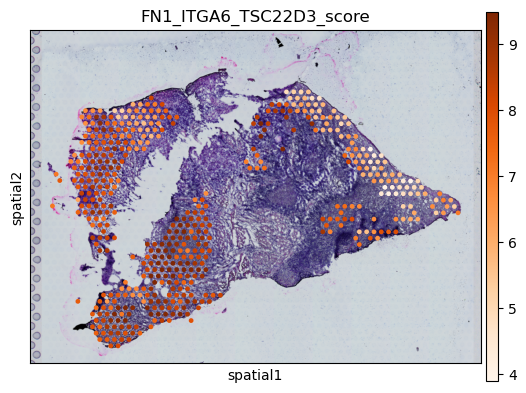

In [33]:
sc.pl.spatial(adata1, color="FN1_ITGA6_TSC22D3_score",cmap='Oranges')